# X-ray reconstruction of a walnut

### Instructions to run this notebook

Download Data82.mat from [here](https://zenodo.org/record/1254206#.W9m2GBNKjUI) and place it in a folder called data. Change the name to walnut82.mat. Alternatively, change the path of the file below. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 


#Some code to beautify the plots
plt.rcParams['figure.figsize'] = [10, 5]
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14

## Load dataset 

In [2]:
from scipy.io import loadmat
mat = loadmat('walnut82.mat')         #Change path here  
from scipy.sparse import csr_matrix

b = mat['m']
A = mat['A']

In [13]:
m,n = A.shape
print('The shape of A is ', A.shape)
print('The number of nonzeros in A is %d and the total number of entries in A is %d' %(A.nnz,m*n))
print('Ratio of nonzero number is ', A.nnz/(m*n))

The shape of A is  (9840, 6724)
The number of nonzeros in A is 970344 and the total number of entries in A is 66164160
Ratio of nonzero number is  0.01466570421206889


The matrix A is mostly full of zeros. Here is a visualization of the first 1000 rows of this matrix.

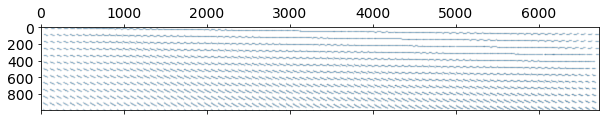

In [12]:
plt.figure(figsize = (10,5))
plt.spy(A[:1000], markersize = 0.005)

### What does the data look like?

A plot of this form is known as the sinogram. It represents all the measured data at all the receivers.

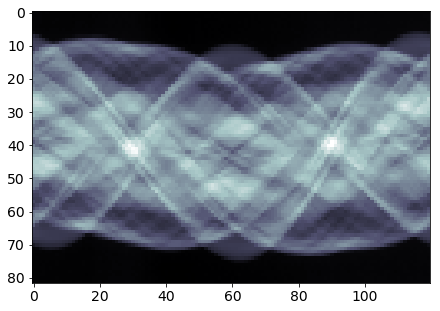

In [6]:
plt.figure()
plt.imshow(b, cmap = 'bone')

### Solution using Tikhonov regularization

In [7]:
from scipy.sparse.linalg import aslinearoperator, LinearOperator

l2 = 10.         #Regularization parameter

# simulate measurement error
bk = b.flatten(order = 'F')

Am = aslinearoperator(A)
Atb =  Am.rmatvec(bk)

Ax = lambda x: Am.rmatvec(Am.matvec(x)) + l2*x

Since the matrices involved are so large, that we cannot use the standard methods we have described so far. We have to use special iterative methods.

In [8]:
from scipy.sparse.linalg import cg

n = A.shape[1]
Aop = LinearOperator((n,n), matvec = Ax)
x, info = cg(Aop, Atb, tol = 1.e-7, maxiter = 100)

## Plot the reconstruction

Text(0.5,1,'Reconstruction')

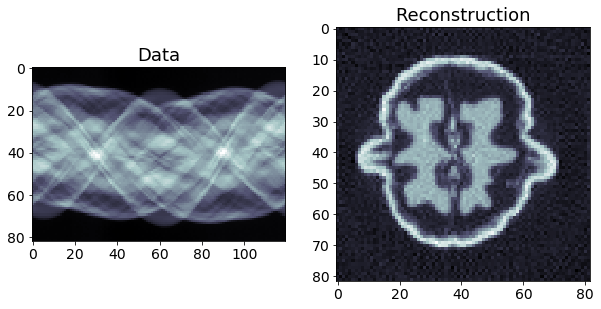

In [9]:
f, (ax1, ax2) = plt.subplots(1,2)
ax1.imshow(b, cmap = 'bone')
ax1.set_title('Data', fontsize = 18)

N = int(np.sqrt(A.shape[1]))
ax2.imshow(x.reshape(N,N).T, cmap = 'bone')
ax2.set_title('Reconstruction', fontsize = 18)

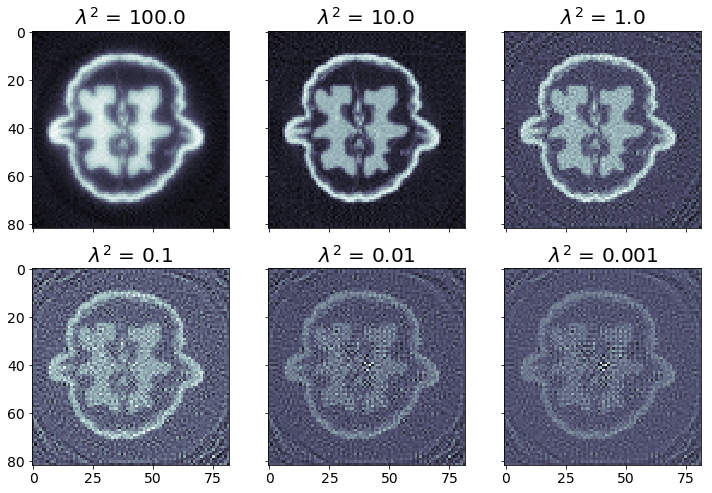

In [10]:
l2lst = [1e2, 1e1,1e0,1e-1,1e-2,1e-3]

from scipy.sparse.linalg import aslinearoperator, LinearOperator, cg
f, axarray = plt.subplots(2,3, sharex = True, sharey = True, figsize = (12,8))
for i, ax in enumerate(axarray.flatten()):
    l2 = l2lst[i]
    
    mat = lambda x: Am.rmatvec(Am.matvec(x)) + l2*x
    H   = LinearOperator(shape = (n,n), matvec = mat)
    
    xk, info = cg(H, Atb, tol = 1.e-7)
    
    ax.imshow( xk.reshape(N,N).T, cmap = 'bone')
    ax.set_title('$\lambda^2$ = ' + str(l2), fontsize = 20)
